## Setup

In [1]:
!pip -q install panns_inference librosa soundfile scikit-learn matplotlib seaborn
!git clone https://github.com/karolpiczak/ESC-50.git

Cloning into 'ESC-50'...
remote: Enumerating objects: 4199, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 4199 (delta 62), reused 34 (delta 34), pack-reused 4130 (from 1)
Receiving objects: 100% (4199/4199), 878.77 MiB | 27.55 MiB/s, done.
Resolving deltas: 100% (292/292), done.
Updating files: 100% (2011/2011), done.


## Loading the data

In [2]:
import numpy as np, pandas as pd, librosa, torch, random

In [3]:
meta = pd.read_csv('ESC-50/meta/esc50.csv')
print(meta.shape, meta.fold.unique(), meta.category.nunique())

(2000, 7) [1 2 3 4 5] 50


In [6]:
def seed_all(s):
    random.seed(s);
    np.random.seed(s);
    torch.manual_seed(s);
    torch.cuda.manual_seed_all(s)

seed_all(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [7]:
def load_audio(fn, sr):
    y, _ = librosa.load(f'ESC-50/audio/{fn}', sr=sr)
    return np.pad(y, (0, max(0, 5*sr - len(y))))[:5*sr]

## Running pretrained model

In [8]:
from panns_inference import AudioTagging
at = AudioTagging(checkpoint_path=None, device=device)   # downloads pretrained CNN14 weights

Checkpoint path: /root/panns_data/Cnn14_mAP=0.431.pth
GPU number: 1


In [9]:
embs = []
files = meta.filename.tolist()
for i in range(0, len(files), 32):
    batch = np.stack([load_audio(f, 32000) for f in files[i:i+32]])
    _, emb = at.inference(batch)          # emb: 2048-dim embedding per clip
    embs.append(emb)

In [11]:
X_pann = np.concatenate(embs); np.save('pann_emb.npy', X_pann)
print(X_pann.shape)

(2000, 2048)


## Pretrained model result

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [13]:
y = meta.target.values; folds = meta.fold.values

In [14]:
def eval_pann(test_fold):
    tr, te = folds != test_fold, folds == test_fold
    sc = StandardScaler().fit(X_pann[tr])
    clf = LogisticRegression(max_iter=3000).fit(sc.transform(X_pann[tr]), y[tr])
    pred = clf.predict(sc.transform(X_pann[te]))
    return (pred == y[te]).mean(), y[te], pred

In [15]:
acc, yt, yp = eval_pann(5)
print('Pretrained (fold 5 test):', acc)

Pretrained (fold 5 test): 0.905


## From-scratch CNN baseline

In [16]:
import torch.nn as nn

In [17]:
def logmel(fn):
    y_ = load_audio(fn, 22050)
    m = librosa.feature.melspectrogram(y=y_, sr=22050, n_fft=1024, hop_length=512, n_mels=64)
    return librosa.power_to_db(m, ref=np.max).astype('float32')

In [18]:
X_mel = np.stack([logmel(f) for f in files])[:, None]   # (2000,1,64,216)
np.save('mel.npy', X_mel)

In [19]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))


In [20]:
def make_cnn():
    return nn.Sequential(block(1,32), block(32,64), block(64,128), block(128,256),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256,50))


In [21]:
def train_cnn(test_fold, epochs=30, seed=42, bs=32, lr=1e-3):
    seed_all(seed)
    tr, te = folds != test_fold, folds == test_fold
    mu, sd = X_mel[tr].mean(), X_mel[tr].std()
    Xtr = torch.tensor((X_mel[tr]-mu)/sd); ytr = torch.tensor(y[tr])
    Xte = torch.tensor((X_mel[te]-mu)/sd).to(device); yte = y[te]
    net = make_cnn().to(device); opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]
            opt.zero_grad()
            loss = nn.functional.cross_entropy(net(Xtr[idx].to(device)), ytr[idx].to(device))
            loss.backward(); opt.step()
        if (ep+1) % 5 == 0:
            net.eval()
            with torch.no_grad(): pred = net(Xte).argmax(1).cpu().numpy()
            print(f'epoch {ep+1}: test acc {(pred==yte).mean():.3f}')
    return (pred == yte).mean(), yte, pred


In [22]:
acc_cnn, yt2, yp2 = train_cnn(5)

epoch 5: test acc 0.448
epoch 10: test acc 0.590
epoch 15: test acc 0.625
epoch 20: test acc 0.625
epoch 25: test acc 0.672
epoch 30: test acc 0.700


## Results and error analysis

In [23]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix

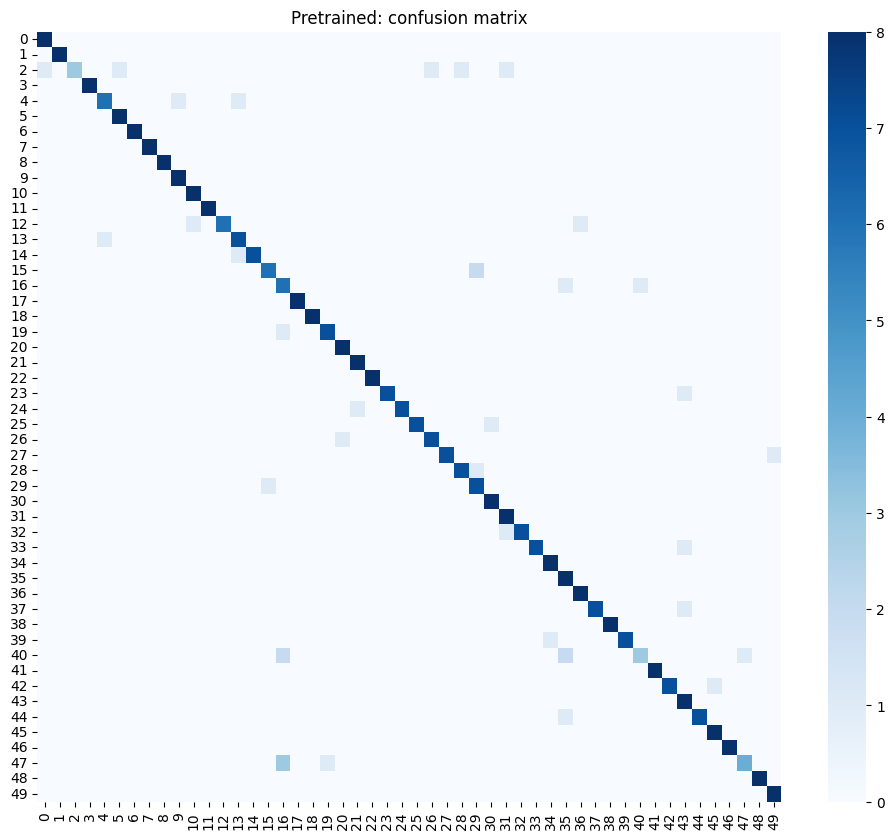

In [25]:
cm = confusion_matrix(yt, yp, labels=range(50))
plt.figure(figsize=(12,10))
sns.heatmap(cm, cmap='Blues')
plt.title('Pretrained: confusion matrix')
plt.show()


In [27]:
pd\
.DataFrame({'model':['Pretrained+LogReg','Scratch CNN'], 'fold5_acc':[acc, acc_cnn]})\
.to_csv('results.csv', index=False)

In [29]:
np.save('/content/drive/MyDrive/Colab Notebooks/ESC/pann_emb.npy', X_pann)
np.save('/content/drive/MyDrive/Colab Notebooks/ESC/mel.npy', X_mel)